# Elastic Net Regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%config InlineBackend.figure_format = 'png'

# Fix the random seed so results are reproducible.
np.random.seed(42)

In [2]:
plt.style.use('ggplot')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2

colors = ['#008fd5', '#fc4f30', '#e5ae38', '#6d904f', '#8b8b8b', '#810f7c', '#137e6d', '#be0119', '#3b638c', '#af6f09','#c79fef', '#80f9ad']

Consider the (hidden) function
$$f(x)=\sin\left(\frac{3\pi x}{10}\right)+\cos\left(\frac{7\pi x}{10}\right)$$

(the same function used in the Gaussian process tutorial, so the two models can be compared).

In [3]:
d = 1

def f(x):
    f = np.sin((3*np.pi)*x/10) + np.cos((7*np.pi)*x/10)
    return(f)

In [4]:
xx = np.linspace(start=0, stop=10, num=1000)
yy = f(xx)

## Generate Data Samples

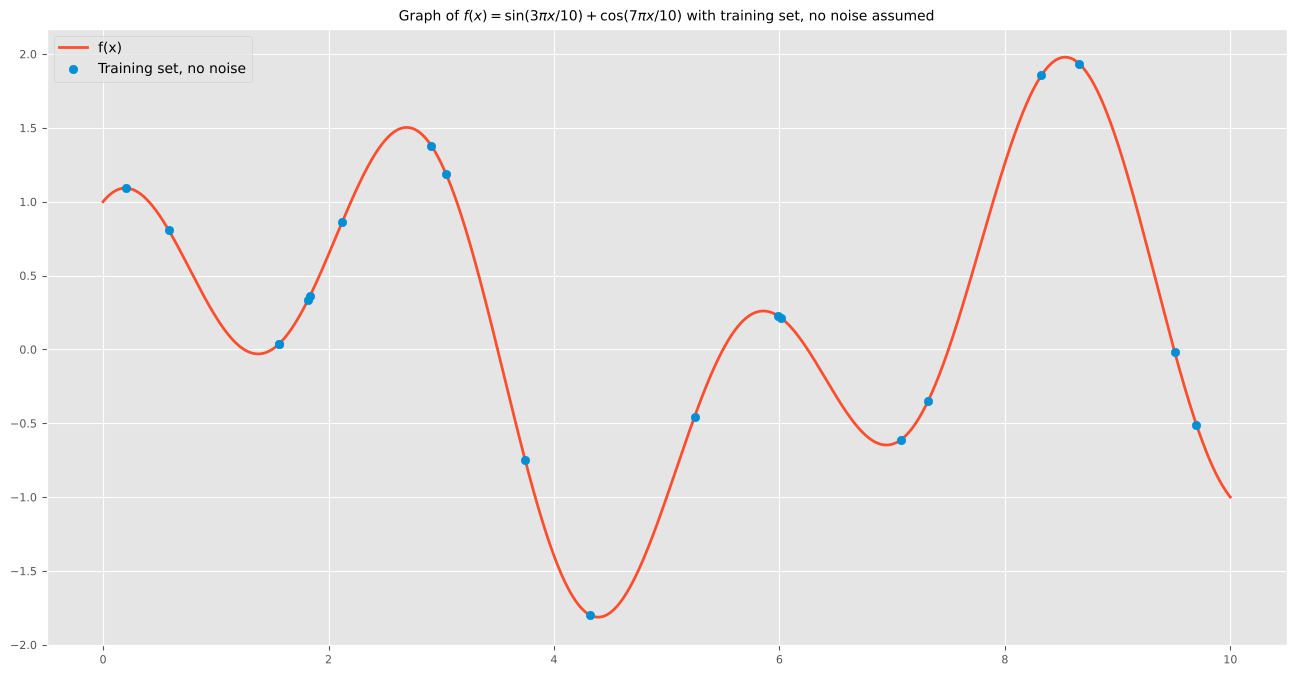

In [5]:
# Number of samples (training set).
# A linear model with many features needs more points than the 10 used for the GP.
n = 20
x = np.random.rand(n)*10
x = np.sort(x)
t = f(x)

fig, ax = plt.subplots()
plt.plot(xx, yy, color=colors[1], label='f(x)', zorder=2)
plt.scatter(x, t, color=colors[0], label='Training set, no noise', zorder=3)

plt.legend(loc='upper left')
plt.title(r'Graph of $f(x) = \sin(3\pi x/10) + \cos(7\pi x/10)$ with training set, no noise assumed');

Next, we generate some training sample observations for the case when a gaussian noise is assumed:

In [6]:
# Error standard deviation.
sigma_n = 0.2

# Errors.
epsilon = np.random.normal(loc=0, scale=sigma_n, size=n)

# Observed target variable.
t_n = t + epsilon

Let us see the error distribution.

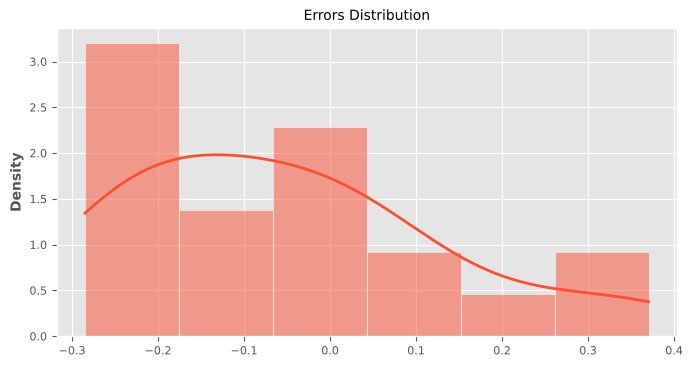

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(x=epsilon, kde=True, stat='density', color=colors[1], ax=ax)
ax.set(title='Errors Distribution');

Let us now visualize the sample data:

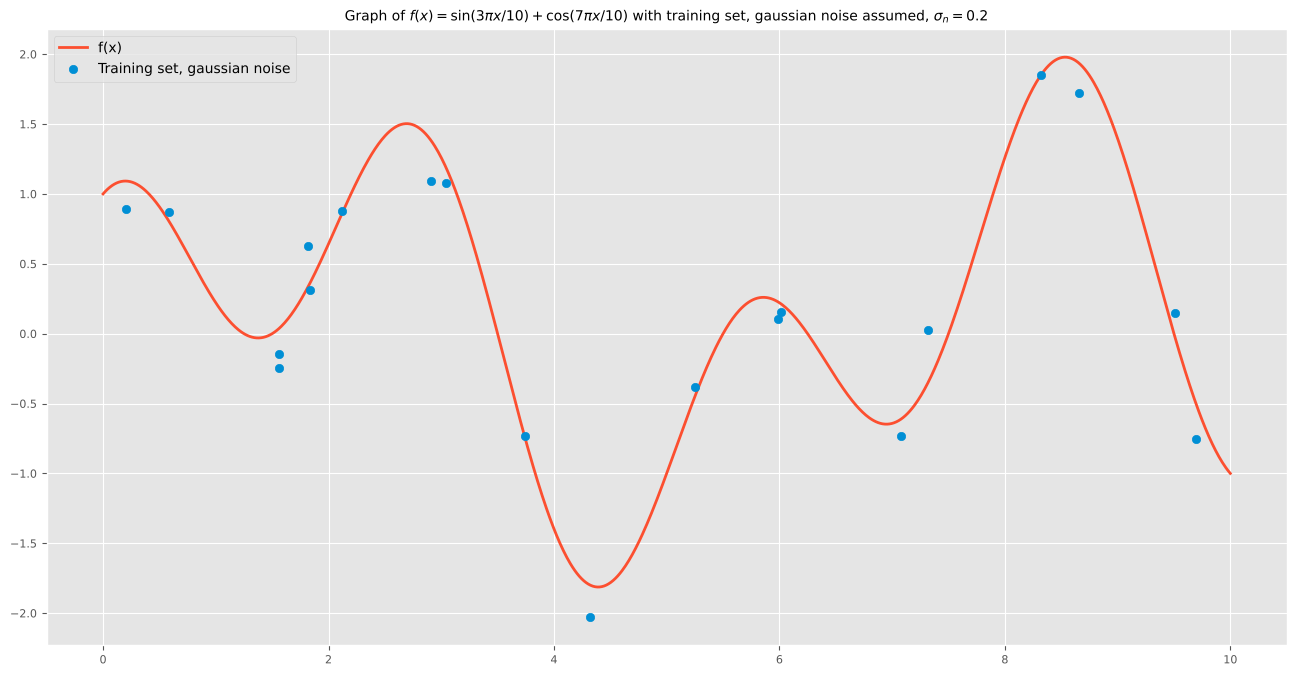

In [8]:
fig, ax = plt.subplots()
plt.plot(xx, yy, color=colors[1], label='f(x)', zorder=2)
plt.scatter(x, t_n, color=colors[0], label='Training set, gaussian noise', zorder=3)

plt.legend(loc='upper left')
plt.title(r'Graph of $f(x) = \sin(3\pi x/10) + \cos(7\pi x/10)$ with training set, gaussian noise assumed, $\sigma_n={}$'.format(sigma_n));

We now consider test data points on which we want to generate predictions.

In [9]:
x_star = xx

## Feature Map

Elastic Net is a **linear** model: it can only fit functions that are linear in the parameters. To fit the non-linear $f$ we map each input $x$ to a vector of features

$$
\phi(x) = \left(\phi_1(x), \ldots, \phi_p(x)\right)^T, \qquad \phi_j(x) = \exp\left(-\frac{(x - c_j)^2}{2\ell^2} \right), \quad j=1,\ldots,p
$$

i.e. gaussian *radial basis functions* (RBF) centered at $p$ equally spaced points $c_j \in [0, 10]$, with width $\ell > 0$ (the same shape as the squared exponential kernel of the Gaussian process tutorial). We then consider the model

$$
t = b + \phi(x)^T w + \varepsilon
$$

with intercept $b \in \mathbb{R}$ and weights $w \in \mathbb{R}^p$. The model is non-linear in $x$ but linear in $(b, w)$.

The intercept is not penalized. To separate it from the weights we **center** each feature (subtract its mean on the training set): the intercept is then simply the mean of the targets. All RBF features take values in $[0, 1]$, so they are already on a comparable scale and we do not rescale them (in general, features with different units must also be divided by their standard deviation, because the penalty is not scale invariant).

In [10]:
def feature_map(x, p=17, l=1, x_min=0, x_max=10):
    """Gaussian RBF features exp(-(x - c_j)^2/(2 l^2)), p centers equally spaced in [x_min, x_max]."""
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    centers = np.linspace(x_min, x_max, p).reshape(1, -1)
    return np.exp(-((x - centers)**2)/(2*l**2))


def center(Phi, mean=None):
    """Center the columns of Phi (with the training mean when given)."""
    if mean is None:
        mean = Phi.mean(axis=0)
    return Phi - mean, mean


def is_positive_definite(A):
    """Check positive definiteness via Cholesky (np.linalg.det under/overflows on large matrices)."""
    try:
        np.linalg.cholesky(A)
        return True
    except np.linalg.LinAlgError:
        return False

Let us select the parameters:

In [11]:
p = 17
l = 1

## Compute Design Matrices

Let us denote by $\Phi(X) \in M_{n \times p}(\mathbb{R})$ and $\Phi(X_*) \in M_{n_* \times p}(\mathbb{R})$ the design matrices whose rows are the feature vectors $\phi(x_i)^T$ of the training and test points. We denote by $Z$ and $Z_*$ their centered versions (both use the mean of the **training** set).

In [12]:
Phi = feature_map(x, p=p, l=l)
Phi_star = feature_map(x_star, p=p, l=l)

Z, Phi_mean = center(Phi)
Z_star, _ = center(Phi_star, Phi_mean)

$\Phi(X)$

In [13]:
print('Shape: {}'.format(Phi.shape))

Shape: (20, 17)


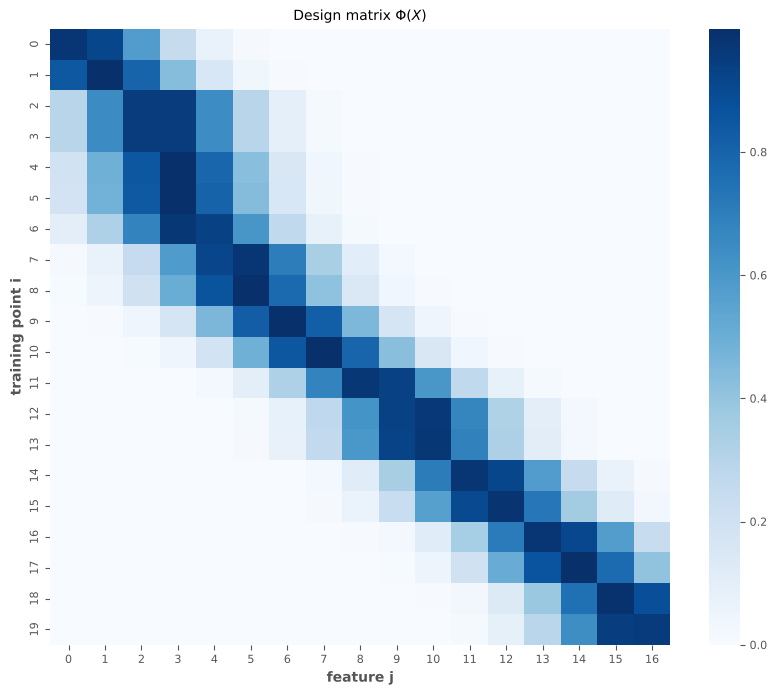

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=Phi, cmap='Blues', ax=ax)
ax.set(xlabel='feature j', ylabel='training point i')
plt.title('Design matrix $\\Phi(X)$');

$\Phi(X_*)$

In [15]:
print('Shape: {}'.format(Phi_star.shape))

Shape: (1000, 17)


Let us plot the features $\phi_j(x)$ on the test points (the columns of $\Phi(X_*)$):

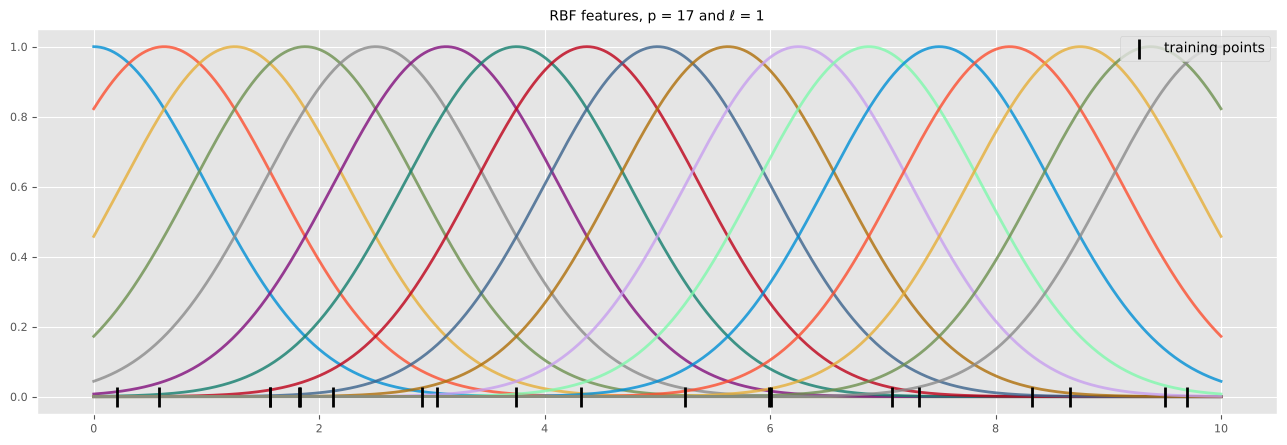

In [16]:
fig, ax = plt.subplots(figsize=(16, 5))
for j in range(p):
    plt.plot(xx, Phi_star[:, j], color=colors[j % len(colors)], alpha=0.8)
plt.scatter(x, np.zeros(n), color='black', marker='|', s=200, zorder=3, label='training points')
ax.set(title=rf'RBF features, p = {p} and $\ell$ = {l}')
ax.legend(loc='upper right');

The matrix $\frac{1}{n} Z^T Z \in M_p(\mathbb{R})$ is the (sample) **covariance matrix** of the features. Neighbouring RBFs overlap, so their features are strongly correlated (*multicollinearity*):

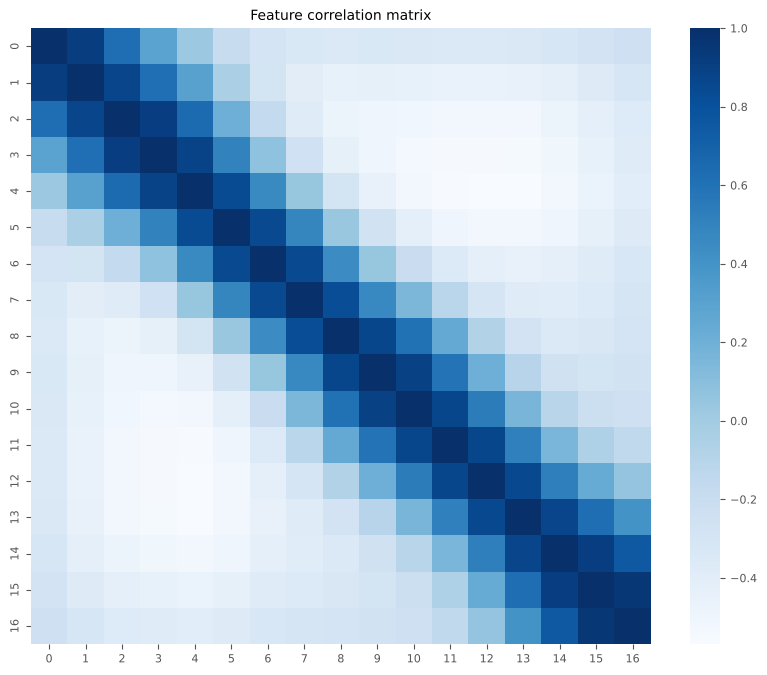

In [17]:
G = Z.T @ Z / n

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=np.corrcoef(Z.T), cmap='Blues', ax=ax)
plt.title('Feature correlation matrix');

As a consequence $Z^T Z$ is positive definite but nearly **singular**: its smallest eigenvalue is almost zero and its condition number is huge, so the least squares problem is very unstable.

In [18]:
print('Positive definite: {}'.format(is_positive_definite(G)))
print('Min eigenvalue: {:.2e}'.format(np.linalg.eigvalsh(G).min()))
print('Condition number of Z^T Z/n: {:.2e}'.format(np.linalg.cond(G)))

Positive definite: True
Min eigenvalue: 2.87e-13
Condition number of Z^T Z/n: 2.82e+12


## Ordinary Least Squares

Without any penalty, the weights are estimated by **ordinary least squares** (OLS):

$$
\hat{w}_{\text{OLS}} = \underset{w}{\arg\min} \; \frac{1}{2n} \lVert y - \bar{y} - Z w \rVert_2^2, \qquad \hat{b} = \bar{y}
$$

whose solution satisfies the normal equations $Z^T Z \, \hat{w} = Z^T (y - \bar{y})$. Predictions on the test points are $\hat{f}_* = \hat{b} + Z_* \hat{w}$.

In [19]:
def fit_ols(Z, y):
    """Least squares weights and intercept (lstsq instead of inverting Z^T Z)."""
    b = y.mean()
    w = np.linalg.lstsq(Z, y - b, rcond=None)[0]
    return w, b


def plot_coefficients(w, title, ax=None, color=colors[0]):
    """Bar chart of the weights w_1, ..., w_p."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(np.arange(1, len(w) + 1), w, color=color)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel='feature j', ylabel='$w_j$', title=title, xticks=np.arange(1, len(w) + 1))
    return ax

Let us first fit the noise-free observations $t$:

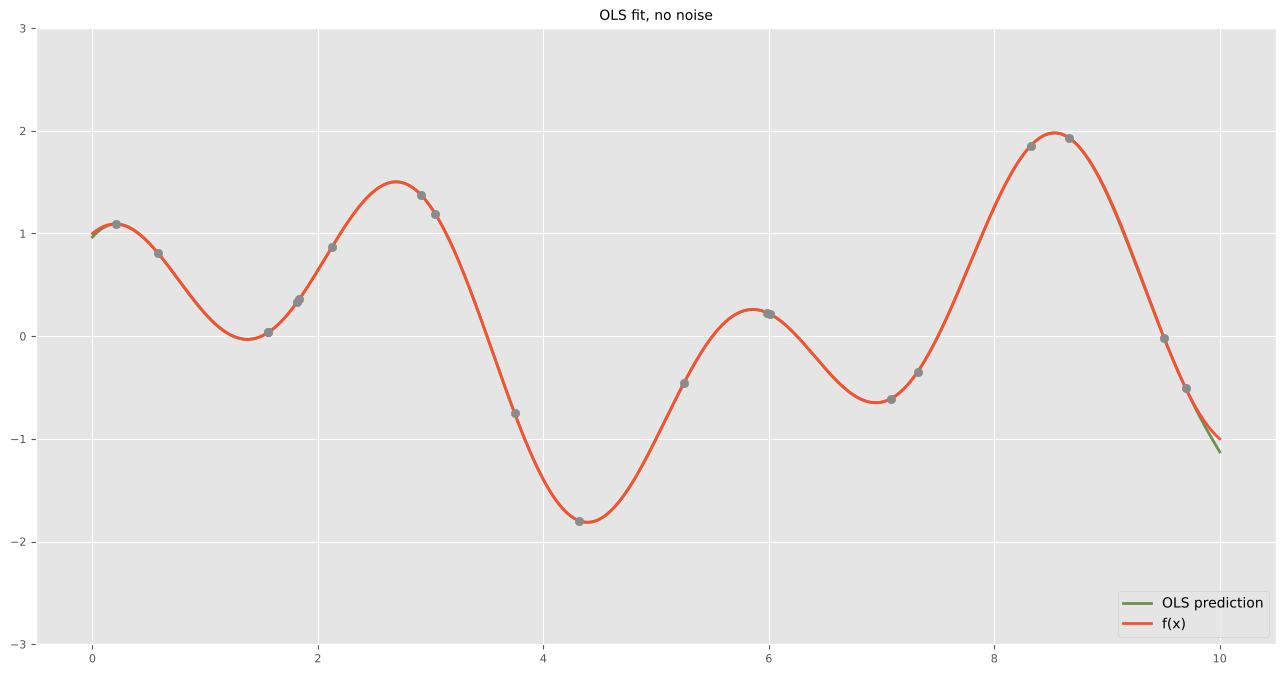

In [20]:
w_ols, b_ols = fit_ols(Z, t)

fig, ax = plt.subplots()
plt.plot(xx, b_ols + Z_star @ w_ols, color=colors[3], label='OLS prediction')
plt.scatter(x, t, color=colors[4], zorder=3)

# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='OLS fit, no noise', ylim=(-3, 3))
ax.legend(loc='lower right');

And now the noisy observations $t_n$:

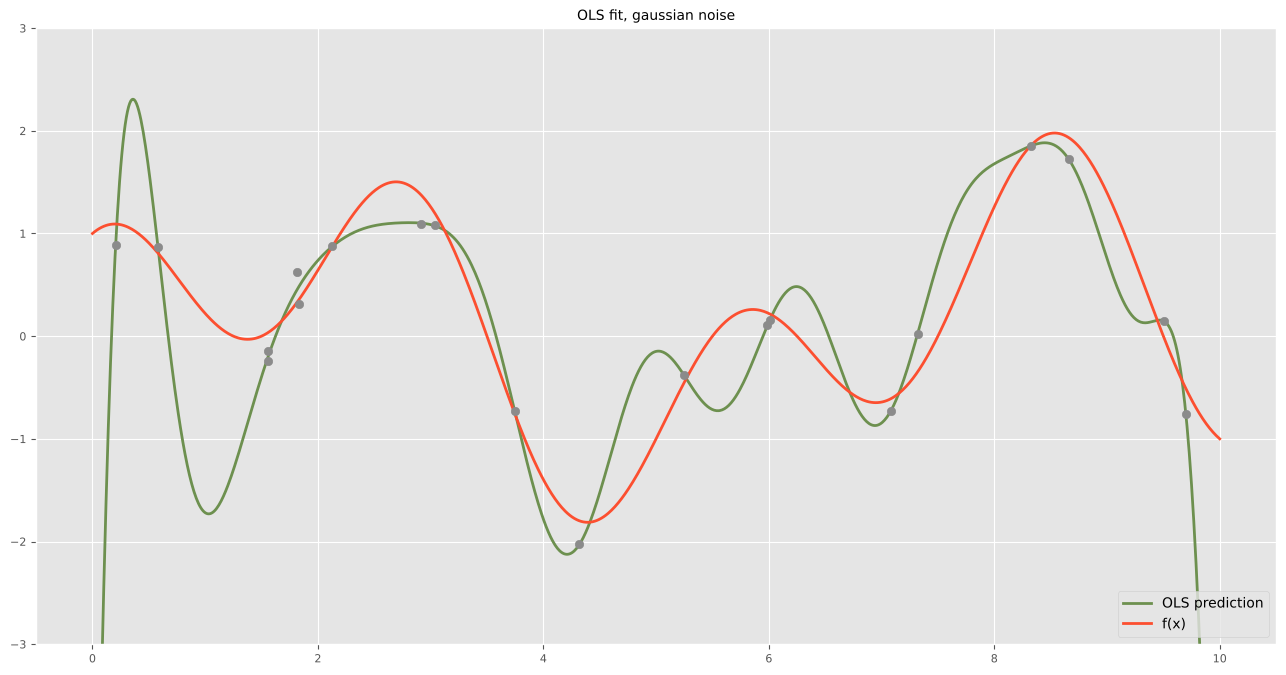

In [21]:
w_ols_n, b_ols_n = fit_ols(Z, t_n)

fig, ax = plt.subplots()
plt.plot(xx, b_ols_n + Z_star @ w_ols_n, color=colors[3], label='OLS prediction')
plt.scatter(x, t_n, color=colors[4], zorder=3)

# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='OLS fit, gaussian noise', ylim=(-3, 3))
ax.legend(loc='lower right');

With noise, OLS uses its $p$ degrees of freedom to chase the errors: the fit **overfits**, oscillating between the training points. The weights are huge and alternate in sign, because highly correlated features cancel each other out:

Max |w_j|: 8293.4


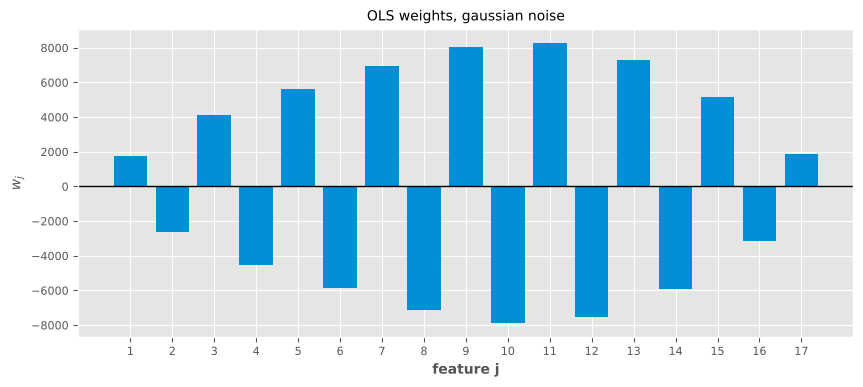

In [22]:
plot_coefficients(w_ols_n, 'OLS weights, gaussian noise');
print('Max |w_j|: {:.1f}'.format(np.abs(w_ols_n).max()))

## Elastic Net Objective

**Regularization** fixes this by adding a penalty on the size of the weights. The **Elastic Net** (Zou & Hastie, 2005) combines the $\ell_1$ penalty of the Lasso and the $\ell_2$ penalty of Ridge regression. Following the Scikit-Learn parametrization, it solves

$$
\hat{w} = \underset{w}{\arg\min} \; \frac{1}{2n} \lVert y - \bar{y} - Z w \rVert_2^2 + \alpha \rho \lVert w \rVert_1 + \frac{\alpha (1 - \rho)}{2} \lVert w \rVert_2^2
$$

where

- $\alpha \geq 0$ is the overall **strength** of the penalty ($\alpha = 0$ gives OLS),
- $\rho \in [0, 1]$ (`l1_ratio`) is the **mix** between the two penalties:
  - $\rho = 0$ is **Ridge** regression: the weights are shrunk towards zero but never exactly zero,
  - $\rho = 1$ is the **Lasso**: many weights are set exactly to zero (*sparsity*, i.e. feature selection),
  - $0 < \rho < 1$ keeps both: sparsity from $\ell_1$, while $\ell_2$ stabilizes the solution and makes correlated features enter the model together (*grouping effect*), where the Lasso would pick one of them almost at random.

The objective is convex, but the $\ell_1$ term is not differentiable at zero, so there is no closed form (except for Ridge).

### Coordinate Descent

The standard algorithm is **coordinate descent**: minimize the objective in one weight $w_j$ at a time, keeping the others fixed, and cycle until the weights stop changing. Denoting by $z_j$ the $j$-th column of $Z$, each one-dimensional problem has the closed-form solution

$$
w_j \leftarrow \frac{S\left(\frac{1}{n} z_j^T r_{(j)}, \; \alpha\rho\right)}{\frac{1}{n}\lVert z_j \rVert_2^2 + \alpha(1 - \rho)}, \qquad r_{(j)} = y - \bar{y} - \sum_{k \neq j} z_k w_k
$$

where $S$ is the **soft-thresholding** operator

$$
S(z, \gamma) = \text{sign}(z) \max(|z| - \gamma, 0).
$$

The numerator is what sets weights exactly to zero; the denominator is the Ridge shrinkage.

In [23]:
def soft_threshold(z, gamma):
    """Soft-thresholding operator S(z, gamma) = sign(z) max(|z| - gamma, 0)."""
    return np.sign(z)*np.maximum(np.abs(z) - gamma, 0)


def elastic_net_cd(Z, y, alpha, l1_ratio=0.5, w_init=None, max_iter=100000, tol=1e-8):
    """Elastic Net by cyclic coordinate descent (Scikit-Learn objective, centered Z).

    Returns the weights w and the intercept b = mean(y).
    """
    n, p = Z.shape
    b = y.mean()
    w = np.zeros(p) if w_init is None else w_init.copy()
    # Residual r = y - b - Z w, updated in place when a weight changes.
    r = y - b - Z @ w
    col_norm = (Z**2).sum(axis=0)/n
    for _ in range(max_iter):
        max_change = 0
        for j in range(p):
            w_j = w[j]
            # z_j^T r_(j) / n, where r_(j) adds back the contribution of feature j.
            rho_j = Z[:, j] @ r/n + col_norm[j]*w_j
            w[j] = soft_threshold(rho_j, alpha*l1_ratio)/(col_norm[j] + alpha*(1 - l1_ratio))
            if w[j] != w_j:
                r -= Z[:, j]*(w[j] - w_j)
                max_change = max(max_change, abs(w[j] - w_j))
        if max_change < tol:
            break
    return w, b

### Ridge as a special case

For $\rho = 0$ the objective is differentiable and the solution has the closed form

$$
\hat{w}_{\text{Ridge}} = \left(\frac{1}{n} Z^T Z + \alpha I\right)^{-1} \frac{1}{n} Z^T (y - \bar{y}).
$$

Observe that adding $\alpha I$ lifts all the eigenvalues of $\frac{1}{n}Z^TZ$ by $\alpha$: this is what cures the ill-conditioning. Let us verify that coordinate descent with $\rho = 0$ recovers the closed form.

In [24]:
def ridge_closed_form(Z, y, alpha):
    """Ridge weights (Scikit-Learn ElasticNet objective with l1_ratio=0)."""
    n, p = Z.shape
    b = y.mean()
    w = np.linalg.solve(Z.T @ Z/n + alpha*np.eye(p), Z.T @ (y - b)/n)
    return w, b


alpha = 0.001
w_cd, _ = elastic_net_cd(Z, t_n, alpha=alpha, l1_ratio=0)
w_ridge, _ = ridge_closed_form(Z, t_n, alpha=alpha)
np.allclose(w_cd, w_ridge, atol=1e-6)

True

Condition number after adding the ridge term:

In [25]:
print('Condition number of Z^T Z/n + alpha I: {:.2e}'.format(np.linalg.cond(G + alpha*np.eye(p))))

Condition number of Z^T Z/n + alpha I: 8.11e+02


## Regularization Path

For fixed $\rho$, the **regularization path** is the curve $\alpha \mapsto \hat{w}(\alpha)$. For large $\alpha$ all weights are zero (the model predicts the constant $\bar{y}$); as $\alpha$ decreases features enter the model one by one and the weights grow towards the OLS solution. Let us compute the path for $\rho = 0.5$, using each solution as the starting point of the next one (*warm start*):

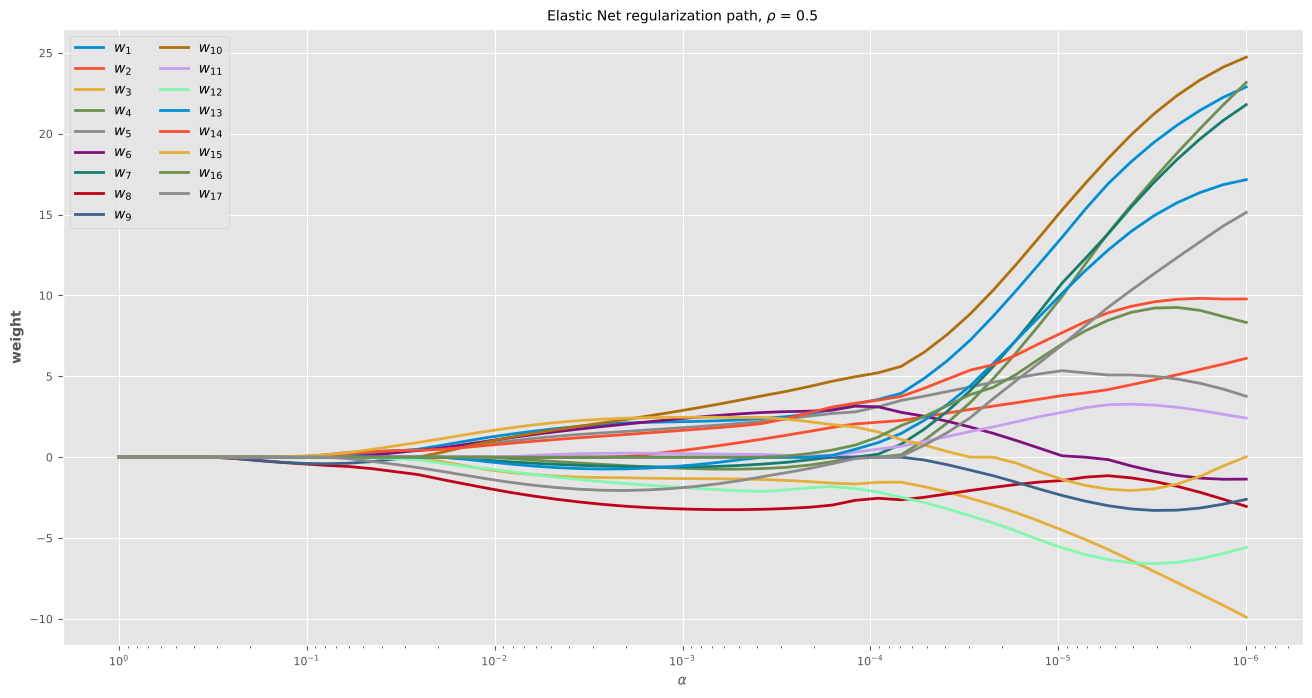

In [26]:
l1_ratio = 0.5
alphas = np.logspace(0, -6, num=50)

coef_path = []
w = None
for a in alphas:
    w, b = elastic_net_cd(Z, t_n, alpha=a, l1_ratio=l1_ratio, w_init=w, tol=1e-6)
    coef_path.append(w)
coef_path = np.array(coef_path)

fig, ax = plt.subplots()
for j in range(p):
    plt.plot(alphas, coef_path[:, j], color=colors[j % len(colors)], label=f'$w_{{{j + 1}}}$')
ax.set(xscale='log', xlabel=r'$\alpha$', ylabel='weight', title=rf'Elastic Net regularization path, $\rho$ = {l1_ratio}')
ax.invert_xaxis()
ax.legend(loc='upper left', ncol=2);

Let us visualize the fitted functions along the path, from the strongest penalty (light) to the weakest one (dark):

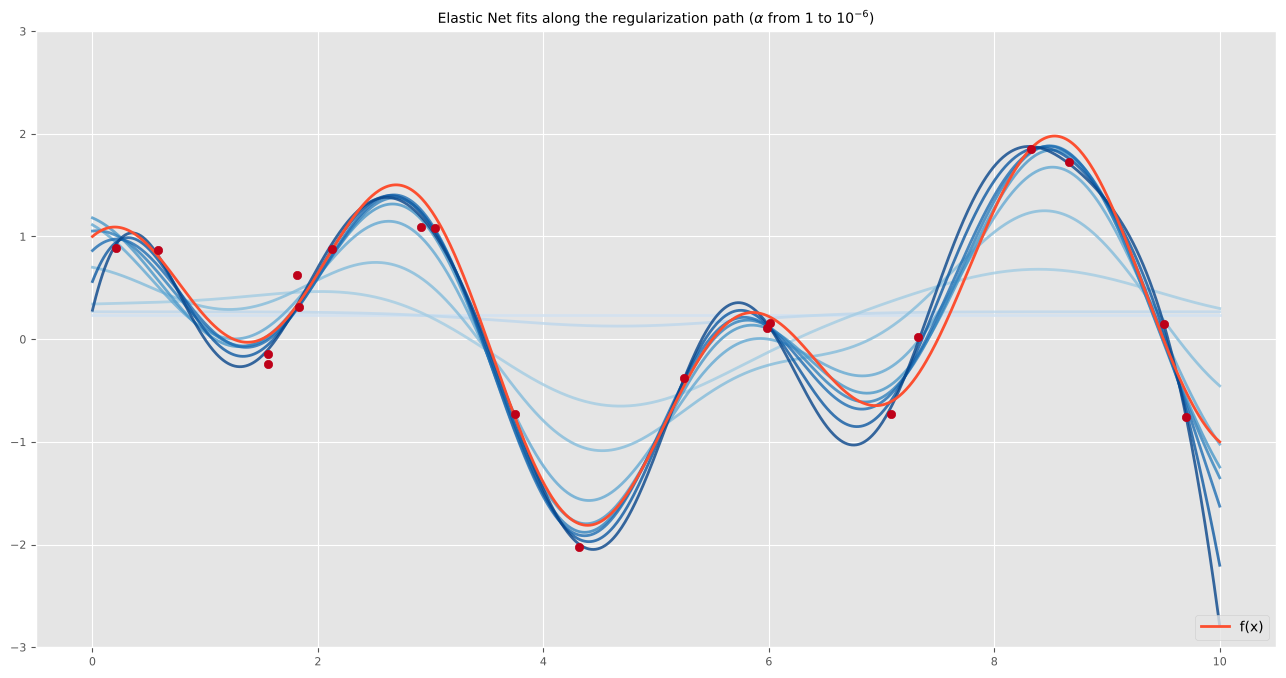

In [27]:
fig, ax = plt.subplots()
cmap = plt.get_cmap('Blues')
for i, a in enumerate(alphas[::5]):
    w_a = coef_path[5*i]
    plt.plot(xx, t_n.mean() + Z_star @ w_a, color=cmap(0.2 + 0.8*i/len(alphas[::5])), alpha=0.8)
plt.scatter(x, t_n, color=colors[7], zorder=3)

# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title=r'Elastic Net fits along the regularization path ($\alpha$ from 1 to $10^{-6}$)', ylim=(-3, 3))
ax.legend(loc='lower right');

## Hyperparameters

We now study the effect of the hyperparameters $\alpha$ and $\rho$ of the Elastic Net objective defined above.

- The hyperparameter $\alpha$ describes the **strength** of the regularization, i.e. the bias-variance trade-off: small $\alpha$ gives a flexible model (low bias, high variance), large $\alpha$ a rigid one (high bias, low variance).

- The hyperparameter $\rho$ describes the **type** of regularization: how many weights are set exactly to zero ($\rho \to 1$) versus shrunk smoothly ($\rho \to 0$).

Let us see some concrete examples:

In [28]:
def fit_and_plot(alpha, l1_ratio):
    """Fit the Elastic Net by coordinate descent, plot the weights and the fit."""
    w, b = elastic_net_cd(Z, t_n, alpha=alpha, l1_ratio=l1_ratio)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 2]})
    plot_coefficients(w, f'Weights, {np.sum(w != 0)} of {p} non-zero', ax=ax1)
    ax2.plot(xx, b + Z_star @ w, color=colors[3], label='prediction')
    ax2.scatter(x, t_n, color=colors[4], zorder=3)
    ax2.plot(xx, yy, color=colors[1], label='f(x)')
    ax2.set(title=rf'Elastic Net fit, $\alpha$ = {alpha} and $\rho$ = {l1_ratio}', ylim=(-3, 3))
    ax2.legend(loc='lower right')
    return w

- $\alpha = 10^{-6}$ and $\rho = 0.5$

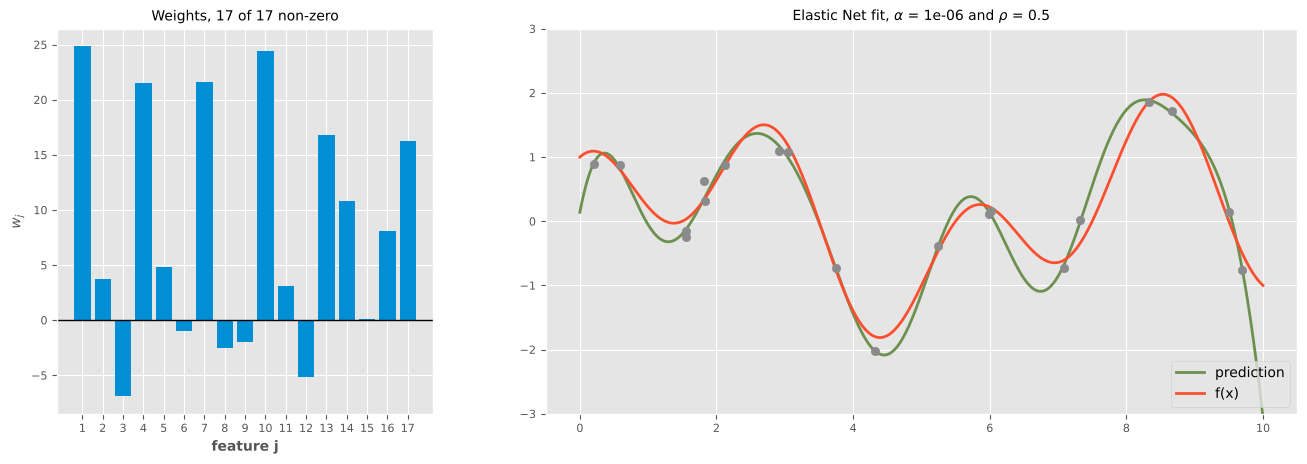

In [29]:
w = fit_and_plot(alpha=1e-6, l1_ratio=0.5)

With a very weak penalty we are close to OLS: the fit still follows the noise and wiggles between the training points, although the weights are already much smaller than the OLS ones (tens instead of thousands).

- $\alpha = 0.05$ and $\rho = 0.5$

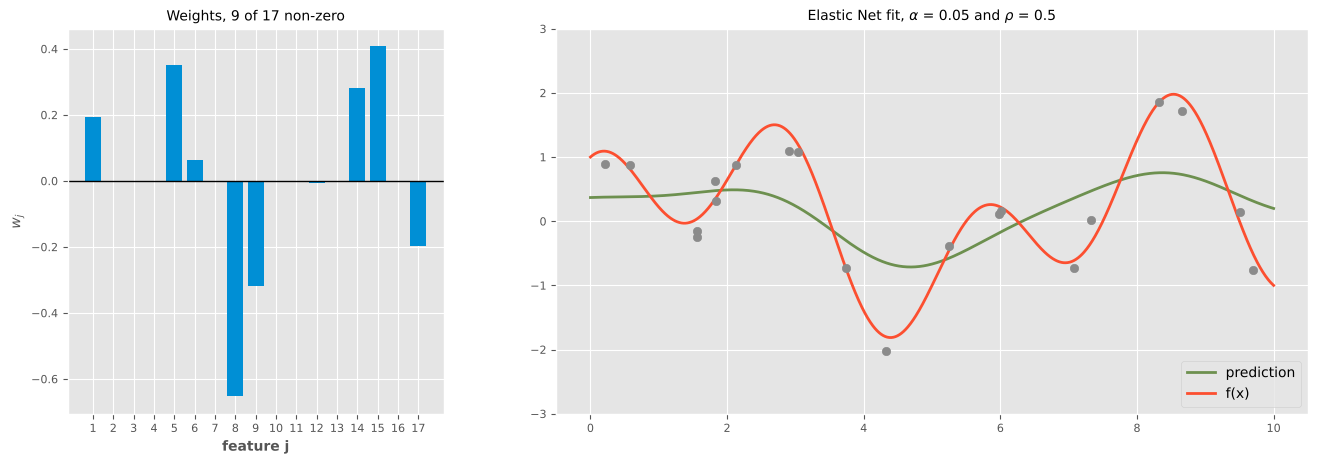

In [30]:
w = fit_and_plot(alpha=0.05, l1_ratio=0.5)

In contrast, a strong penalty keeps only some of the weights, and shrinks them heavily: the model is too rigid and **underfits** (it cannot even reach the peaks of $f$).

Hence, we see that the hyperparameter $\alpha$ encodes the "complexity" of the model. Let us now fix an intermediate $\alpha$ and change the mix $\rho$:

- $\alpha = 0.001$ and $\rho = 0$ (Ridge)

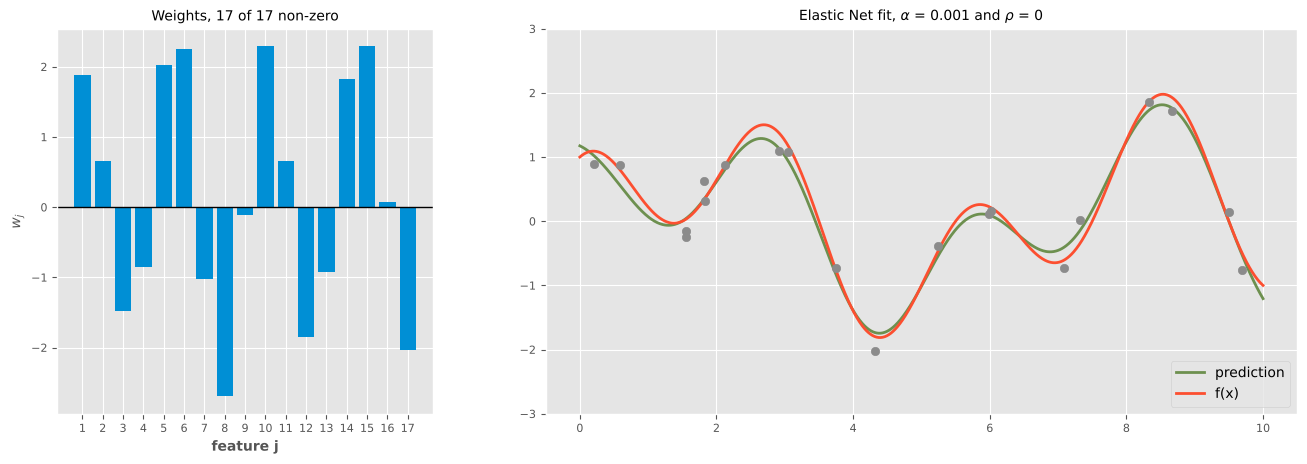

In [31]:
w = fit_and_plot(alpha=0.001, l1_ratio=0)

- $\alpha = 0.001$ and $\rho = 1$ (Lasso)

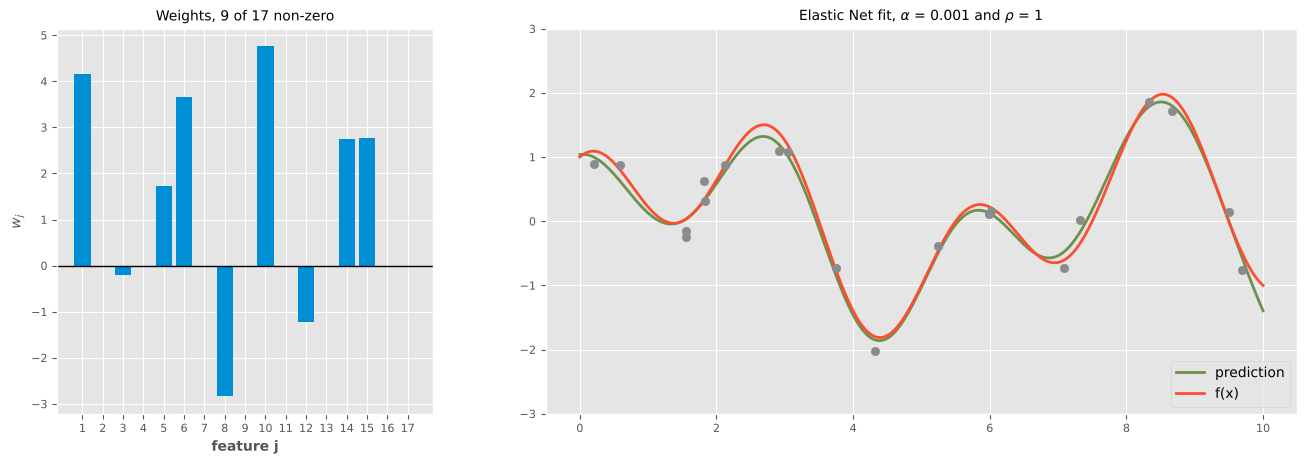

In [32]:
w = fit_and_plot(alpha=0.001, l1_ratio=1)

- $\alpha = 0.001$ and $\rho = 0.5$ (Elastic Net)

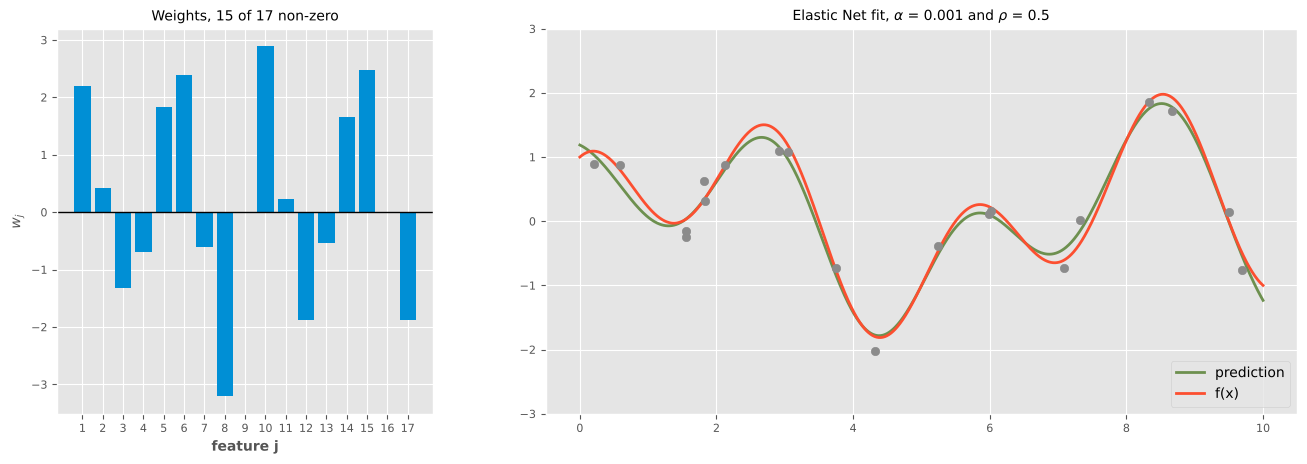

In [33]:
w = fit_and_plot(alpha=0.001, l1_ratio=0.5)

Ridge keeps all $p$ features with small weights, while the Lasso sets most of them exactly to zero and represents $f$ with a few powers only. The Elastic Net lies in between. The hyperparameter $\rho$ encodes the **sparsity** of the fit.

## ElasticNet from Scikit-Learn

### Model Object

Scikit-Learn implements the same objective (also solved by coordinate descent) in [`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html). The feature map becomes a step of a [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) (wrapped in a [`FunctionTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html)), while `ElasticNet` centers the features itself to fit the intercept:

In [34]:
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import ElasticNet, ElasticNetCV
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# Define hyperparameters.
alpha = 0.001
l1_ratio = 0.5

# Define model object: RBF features, Elastic Net.
model = Pipeline([
    ('rbf', FunctionTransformer(feature_map, kw_args={'p': p, 'l': l})),
    ('enet', ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=100000, tol=1e-10)),
])

We reshape the variables into matrix form.

In [35]:
X = x.reshape(-1, d)
X_star = xx.reshape(-1, d)

In [36]:
model.fit(X, t_n);

Let us check that Scikit-Learn finds the same weights as our coordinate descent implementation. Scikit-Learn reports the intercept for the uncentered features, $\bar{y} - \bar{\phi}^T \hat{w}$, where $\bar{\phi}$ is the training mean of the features:

In [37]:
w_cd, b_cd = elastic_net_cd(Z, t_n, alpha=alpha, l1_ratio=l1_ratio, tol=1e-12)
print('Max |w_sklearn - w_cd|: {:.2e}'.format(np.abs(model['enet'].coef_ - w_cd).max()))
print('Intercepts: {:.6f} vs {:.6f}'.format(model['enet'].intercept_, b_cd - Phi_mean @ w_cd))

Max |w_sklearn - w_cd|: 5.54e-09
Intercepts: -0.724641 vs -0.724641


### ElasticNetCV

So far we have chosen $\alpha$ and $\rho$ by hand. In the Gaussian process the hyperparameters were chosen by maximizing the log-marginal likelihood; for the Elastic Net they are usually chosen by **$k$-fold cross-validation**: the training set is split into $k$ folds, the model is fitted on $k-1$ folds and its mean squared error (MSE) is measured on the held-out fold, for every pair $(\alpha, \rho)$ on a grid. The pair with the smallest average error is selected and the model is refitted on all the data. [`ElasticNetCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html) does all of this efficiently using the regularization path.

Note that the training points are sorted by $x$, so the folds must be **shuffled**: otherwise each fold would be a contiguous interval and the model would be validated on extrapolation.

In [38]:
# Grid of hyperparameters.
l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]
alphas = np.logspace(-6, 0, num=60)

model_cv = Pipeline([
    ('rbf', FunctionTransformer(feature_map, kw_args={'p': p, 'l': l})),
    ('enet', ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                          max_iter=100000)),
])
# The smallest alphas of the grid make coordinate descent converge slowly on these nearly
# collinear features: the resulting ConvergenceWarnings do not affect the selected model.
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    model_cv.fit(X, t_n)

enet_cv = model_cv['enet']
print('Selected alpha: {:.2e}'.format(enet_cv.alpha_))
print('Selected l1_ratio: {}'.format(enet_cv.l1_ratio_))
print('Non-zero weights: {} of {}'.format(np.sum(enet_cv.coef_ != 0), p))

Selected alpha: 5.57e-04
Selected l1_ratio: 0.99
Non-zero weights: 9 of 17


Let us plot the cross-validation error as a function of $\alpha$, for each value of $\rho$:

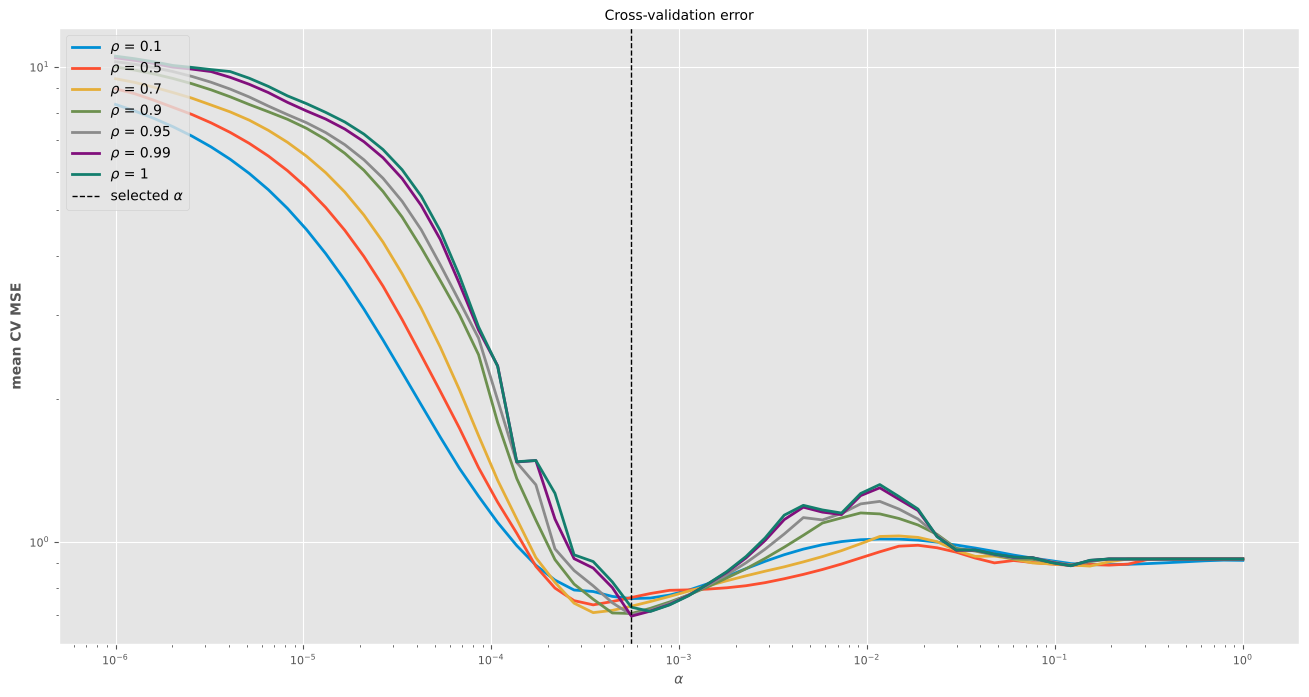

In [39]:
fig, ax = plt.subplots()
# mse_path_ has shape (n_l1_ratio, n_alphas, n_folds); alphas_ is shared by all l1_ratios
# when the grid is given explicitly, otherwise it has one row per l1_ratio.
alphas_grid = np.broadcast_to(enet_cv.alphas_, enet_cv.mse_path_.shape[:2])
for i, r in enumerate(l1_ratios):
    plt.plot(alphas_grid[i], enet_cv.mse_path_[i].mean(axis=1), color=colors[i], label=rf'$\rho$ = {r}')
plt.axvline(enet_cv.alpha_, color='black', linestyle='--', linewidth=1, label=r'selected $\alpha$')
ax.set(xscale='log', yscale='log', xlabel=r'$\alpha$', ylabel='mean CV MSE', title='Cross-validation error')
ax.legend(loc='upper left');

### Predictions

In [40]:
# Make the prediction on test set.
y_pred = model_cv.predict(X_star)

In [41]:
y_pred.shape

(1000,)

Let us plot the prediction.

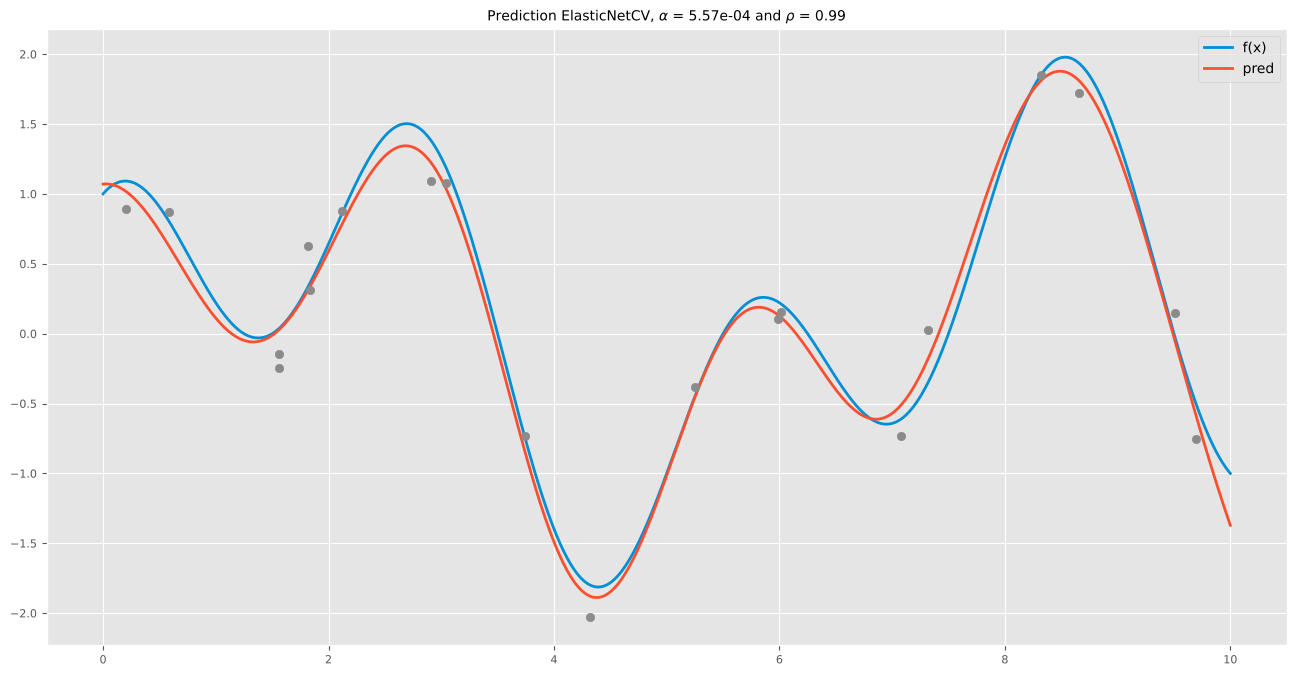

In [42]:
fig, ax = plt.subplots()

# Plot "true" function.
plt.plot(xx, yy, color=colors[0], label='f(x)')
# Plot prediction.
plt.plot(xx, y_pred, color=colors[1], label='pred')
plt.scatter(x, t_n, color=colors[4], zorder=3)
plt.title(rf'Prediction ElasticNetCV, $\alpha$ = {enet_cv.alpha_:.2e} and $\rho$ = {enet_cv.l1_ratio_}')
plt.legend(loc='upper right');

### Prediction Interval

Unlike the Gaussian process, the Elastic Net is not a Bayesian model: it returns a single function, not a posterior distribution, so there are no credible intervals. A simple way to quantify the uncertainty of the fit is the **bootstrap**: we resample the training set with replacement, refit the model on each resample (with the selected $\alpha$ and $\rho$) and look at the spread of the predictions.

Note that this is a frequentist variability band for the fitted function, not a Bayesian credible interval, and that it ignores the bias introduced by the penalty.

In [43]:
# Fixed model with the hyperparameters selected by cross-validation.
model_boot = Pipeline([
    ('rbf', FunctionTransformer(feature_map, kw_args={'p': p, 'l': l})),
    ('enet', ElasticNet(alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, max_iter=100000)),
])

# Generate bootstrap predictions.
rng = np.random.default_rng(42)
n_boot = 100
y_hat_samples = np.empty((len(xx), n_boot))
for i in range(n_boot):
    idx = rng.integers(0, n, size=n)
    y_hat_samples[:, i] = model_boot.fit(X[idx], t_n[idx]).predict(X_star)
# Compute the mean of the sample.
y_hat = y_hat_samples.mean(axis=1)
# Compute the standard deviation of the sample.
y_hat_sd = y_hat_samples.std(axis=1)

We now plot the corridor associated with two standard deviations. With only 20 training points the band is wide, especially near the edges of the interval and in the gaps between training points, where each bootstrap resample may contain no data at all.

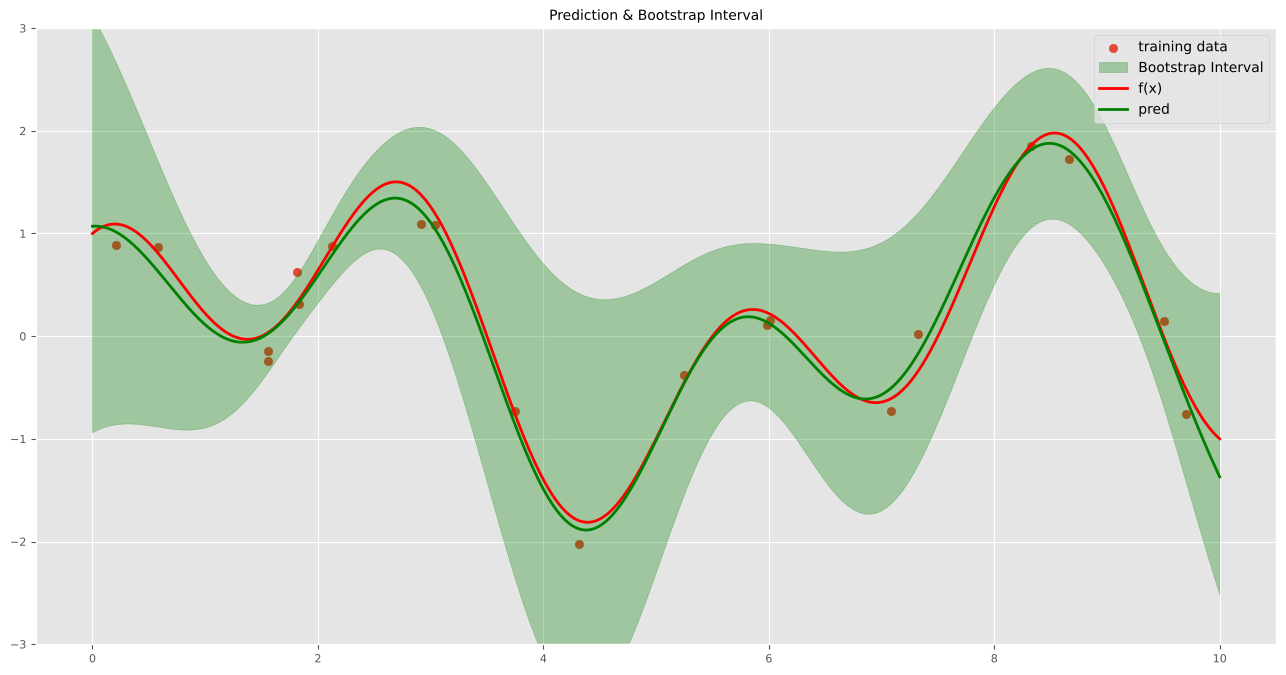

In [44]:
fig, ax = plt.subplots()

# Plot training data.
plt.scatter(x, t_n, label='training data');
# Plot corridor.
plt.fill_between(xx, (y_hat - 2*y_hat_sd), (y_hat + 2*y_hat_sd),
    color='green',
    alpha = 0.3,
    label='Bootstrap Interval'
)
# Plot "true" function.
plt.plot(xx, yy, color='red', label='f(x)');
# Plot prediction.
plt.plot(xx, y_pred, color='green', label='pred')
ax.set(title='Prediction & Bootstrap Interval', ylim=(-3, 3))
ax.legend(loc='upper right');

## Summary & Final Example

In this tutorial we have studied the fundamentals of Elastic Net regression: the penalized least squares objective, coordinate descent with soft-thresholding, and the role of $\alpha$ (strength) and $\rho$ (sparsity). Let us finalize with a self-contained example where we only use the tools from Scikit-Learn, in the setting the Elastic Net was designed for: **more features than samples** ($p > n$), with groups of **correlated** features, of which only a few are relevant. This is typical of preclinical data, e.g. a panel of biomarkers measured on a small number of subjects.

### Construct Training Set

In [45]:
# Number of training points.
n = 100
# Number of features.
p = 200
# Groups of correlated features: 5 groups of 10 features each.
n_groups, group_size = 5, 10
# Correlation of the features within a group.
rho_group = 0.95
# Error standard deviation.
sigma_n = 5


def generate_features(n_samples, rng):
    """Correlated groups (shared latent factor + noise) followed by independent features."""
    latent = rng.normal(size=(n_samples, n_groups))
    noise = rng.normal(size=(n_samples, n_groups*group_size))
    grouped = np.sqrt(rho_group)*np.repeat(latent, group_size, axis=1) + np.sqrt(1 - rho_group)*noise
    independent = rng.normal(size=(n_samples, p - n_groups*group_size))
    return np.hstack([grouped, independent])


# True weights: only the first 3 groups are relevant, every feature of a group has the same weight.
w_true = np.zeros(p)
for g, value in enumerate([1.0, -1.0, 0.5]):
    w_true[g*group_size:(g + 1)*group_size] = value

rng = np.random.default_rng(42)
X = generate_features(n, rng)
# Observed target variable.
y = X @ w_true + rng.normal(scale=sigma_n, size=n)

### Construct Test Set

In [46]:
n_star = 1000
X_star = generate_features(n_star, rng)
y_star = X_star @ w_true + rng.normal(scale=sigma_n, size=n_star)

### Define Models

In [47]:
from sklearn.linear_model import LassoCV, RidgeCV

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Ridge': Pipeline([('scaler', StandardScaler()), ('model', RidgeCV(alphas=np.logspace(-3, 3, num=60)))]),
    'Lasso': Pipeline([('scaler', StandardScaler()), ('model', LassoCV(cv=cv, max_iter=100000))]),
    'Elastic Net': Pipeline([('scaler', StandardScaler()),
                             ('model', ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95], cv=cv, max_iter=100000))]),
}

### Model Fit + Predictions

In [48]:
from sklearn.metrics import mean_squared_error

y_preds = {}
for name, model in models.items():
    # Fit to data, choosing the hyperparameters by cross-validation.
    model.fit(X, y)
    # Make the prediction on test set.
    y_preds[name] = model.predict(X_star)
    coef = model['model'].coef_
    selected = np.flatnonzero(coef)
    print('{:<12} test MSE = {:5.2f}   non-zero weights = {:3d}   relevant features selected = {:2d} of {}'.format(
        name, mean_squared_error(y_star, y_preds[name]), len(selected), np.sum(w_true[selected] != 0), np.sum(w_true != 0)))

enet = models['Elastic Net']['model']
print('Elastic Net: alpha = {:.3f}, l1_ratio = {}'.format(enet.alpha_, enet.l1_ratio_))

Ridge        test MSE = 36.40   non-zero weights = 200   relevant features selected = 30 of 30
Lasso        test MSE = 27.40   non-zero weights =  27   relevant features selected = 18 of 30


Elastic Net  test MSE = 26.96   non-zero weights =  34   relevant features selected = 22 of 30
Elastic Net: alpha = 0.802, l1_ratio = 0.9


### Visualize Results

Let us compare the estimated weights of the first 60 features (the 5 correlated groups, separated by dotted lines, and 10 independent features) with the true ones:

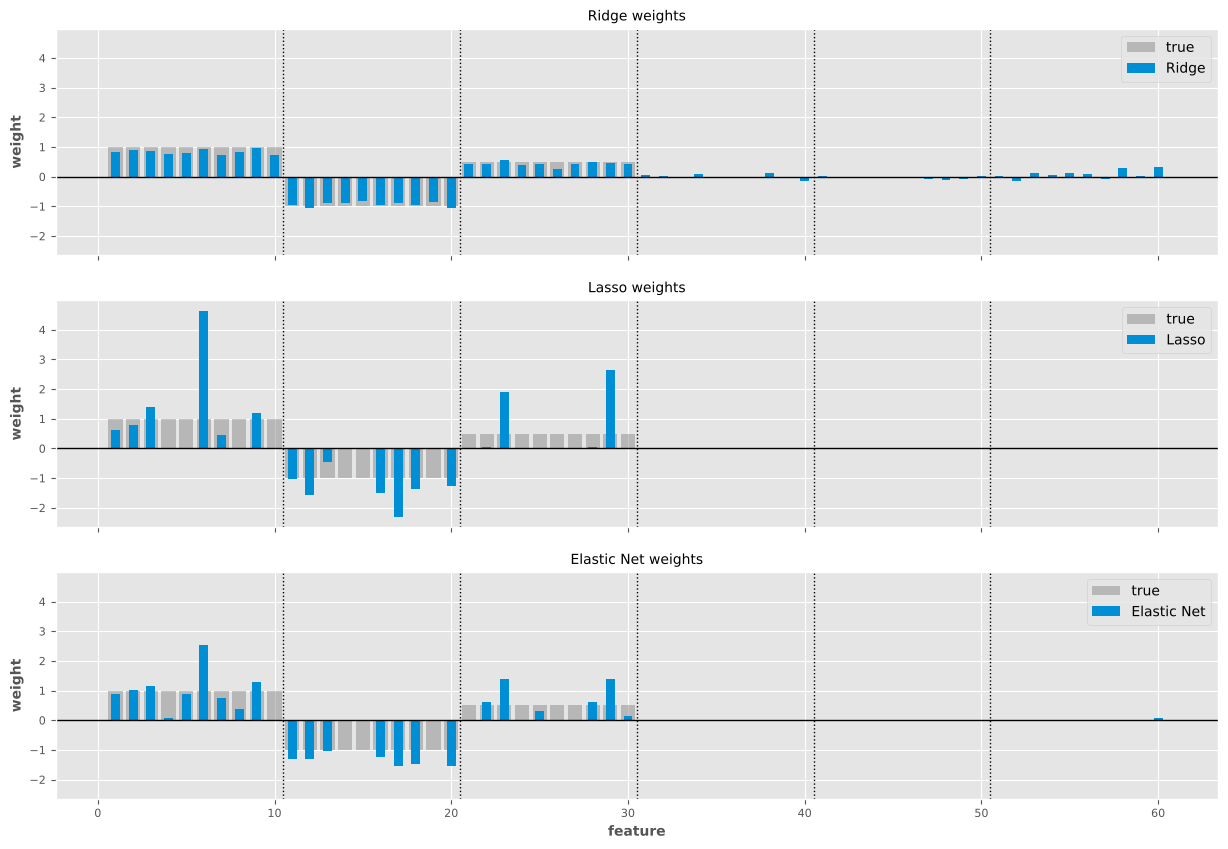

In [49]:
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True, sharey=True)
idx = np.arange(1, 61)
for ax, name in zip(axes, models):
    # Weights on the original scale of the features.
    coef = models[name]['model'].coef_/models[name]['scaler'].scale_
    ax.bar(idx, w_true[:60], color=colors[4], alpha=0.5, label='true')
    ax.bar(idx, coef[:60], color=colors[0], width=0.5, label=name)
    for g in range(1, n_groups + 1):
        ax.axvline(g*group_size + 0.5, color='black', linestyle=':', linewidth=1)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(ylabel='weight', title=f'{name} weights')
    ax.legend(loc='upper right')
axes[-1].set(xlabel='feature');

The Lasso tends to select only some features from each relevant group, almost at random, and misses part of the signal. Ridge keeps all 200 features, so the irrelevant ones add noise. The Elastic Net keeps the relevant groups **together** (*grouping effect*) while setting most irrelevant features to zero. Finally, let us compare the predictions on the test set: both sparse models clearly beat Ridge, with the Elastic Net slightly ahead of the Lasso.

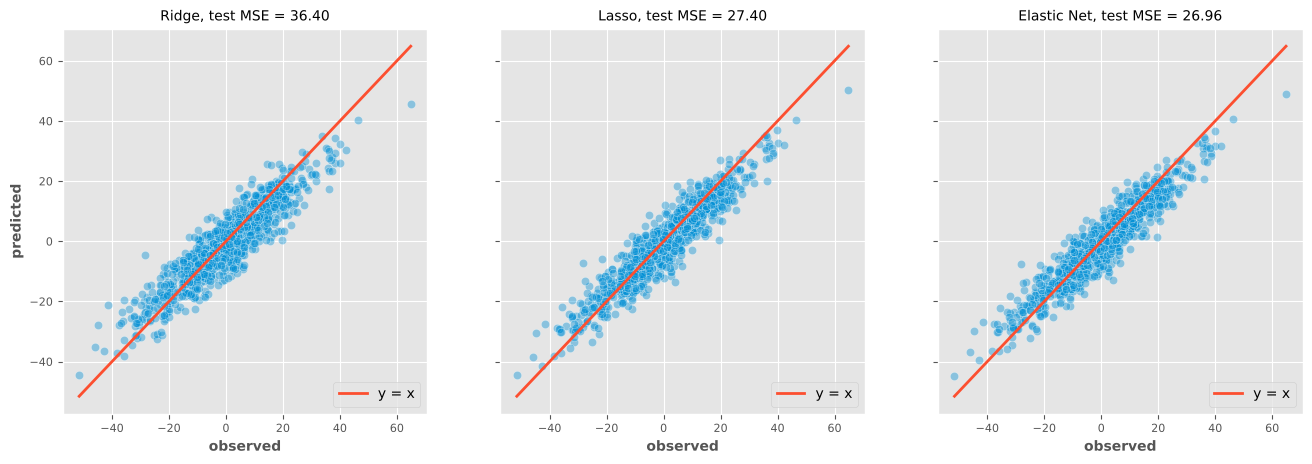

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [y_star.min(), y_star.max()]
for ax, name in zip(axes, models):
    sns.scatterplot(x=y_star, y=y_preds[name], color=colors[0], alpha=0.4, ax=ax)
    ax.plot(lims, lims, color=colors[1], label='y = x')
    ax.set(xlabel='observed', ylabel='predicted',
           title='{}, test MSE = {:.2f}'.format(name, mean_squared_error(y_star, y_preds[name])))
    ax.legend(loc='lower right');